
# A. Business Understanding and Data Understanding


## A1. Business Understanding
### Background on Lending Club
LendingClub is an American peer-to-peer lending company, headquartered in San Francisco, California. It is the world's largest peer-to-peer lending platform.

LendingClub enables borrowers to create unsecured personal loans between \\$1,000 and \\$40,000. Investors can search and browse the loan listings on LendingClub website and select loans that they want to invest in based on the information supplied about the borrower, amount of loan, loan grade, and loan purpose, with the minimum investment of $25 per note. Investors make money from interest. LendingClub makes money by charging borrowers an origination fee and investors a service fee.

### Business Goal
To identify loans to invest based on the loan portfolio performance. Potential loans are those demonstrates a high likelihood to be fully paid off. 

### Problem Solving Strategy
- Build a binary classifier: to predict which loans would be fully paid off
- From these loans, I will calculate the annual return to determine the paid off or charged off potential.

## A2. Data Understanding
The data understanding phase starts with an initial data collection and proceeds with activities in order to get familiar with the data, to identify data quality problems, to discover first insights into the data, or to detect interesting subsets to form hypotheses for hidden information.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go

#display all dataframe columns in df.head()
pd.options.display.max_columns = None
#display long string in datafame
pd.options.display.max_colwidth = 300

#filter out warning messages
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

import os
for dirname, _, filenames in os.walk('/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
from supabase import create_client, Client

/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw/.DS_Store
/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw/.gitkeep
/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw/lending_club_2007_2011_6_states.csv
/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw/data_dictionary.csv


### A2.a. Data File

The data file **lending_club_2007_2011_6_states.csv** contains the loan and borrower information for loans initiated from 2007 to 2011 in six states, California, New York, Florida, Texas, New Jersey and Illinois.

The data dictionary file **data_dictionary.csv** contains descriptions of all the columns in the data file.

#### Data Dictionary

In [2]:
data_dict = pd.read_csv('/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw/data_dictionary.csv')
data_dict

,ColumnName,Description
0,acc_now_delinq,The number of accounts on which the borrower is now delinquent.
1,addr_state,The state provided by the borrower in the loan application
2,annual_inc,The self-reported annual income provided by the borrower during registration.
3,application_type,Indicates whether the loan is an individual application or a joint application with two co-borrowers
4,chargeoff_within_12_mths,Number of charge-offs within 12 months
5,collection_recovery_fee,post charge off collection fee
6,collections_12_mths_ex_med,Number of collections in 12 months excluding medical collections
7,debt_settlement_flag,"Flags whether or not the borrower, who has charged-off, is working with a debt-settlement company."
8,debt_settlement_flag_date,The most recent date that the Debt_Settlement_Flag has been set
9,delinq_2yrs,The number of 30+ days past-due incidences of delinquency in the borrower's credit file for the past 2 years


#### Loan Data

In [3]:
loan_df = pd.read_csv('/Users/miu/Data Science/DS Projects/lending_club_loan_portfolio/data/raw/lending_club_2007_2011_6_states.csv')
loan_df.head()

,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,acc_now_delinq,chargeoff_within_12_mths,delinq_amnt,pub_rec_bankruptcies,tax_liens,hardship_flag,disbursement_method,debt_settlement_flag,debt_settlement_flag_date
0,1,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252,Not Verified,Dec-11,Fully Paid,n,small_business,real estate business,606xx,IL,8.72,0,Nov-01,2,NaN,NaN,2,0,2956,98.5,10,f,0,0,3005.666844,3005.67,2400.00,605.67,0.00,0.00,0.00,Jun-14,649.91,NaN,Jun-17,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN
1,2,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200,Source Verified,Dec-11,Fully Paid,n,other,personel,917xx,CA,20.00,0,Feb-96,1,35.0,NaN,10,0,5598,21.0,37,f,0,0,12231.890000,12231.89,10000.00,2214.92,16.97,0.00,0.00,Jan-15,357.48,NaN,Apr-16,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN
2,3,3000,3000,3000.0,36 months,18.64,109.43,E,E1,MKC Accounting,9 years,RENT,48000,Source Verified,Dec-11,Fully Paid,n,car,Car Downpayment,900xx,CA,5.35,0,Jan-07,2,NaN,NaN,4,0,8221,87.5,4,f,0,0,3939.135294,3939.14,3000.00,939.14,0.00,0.00,0.00,Jan-15,111.34,NaN,Dec-14,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN
3,4,5600,5600,5600.0,60 months,21.28,152.39,F,F2,NaN,4 years,OWN,40000,Source Verified,Dec-11,Charged Off,n,small_business,Expand Business & Buy Debt Portfolio,958xx,CA,5.55,0,Apr-04,2,NaN,NaN,11,0,5210,32.6,13,f,0,0,647.500000,647.50,162.02,294.94,0.00,190.54,2.09,Apr-12,152.39,NaN,Oct-16,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN
4,5,5375,5375,5350.0,60 months,12.69,121.45,B,B5,Starbucks,< 1 year,RENT,15000,Verified,Dec-11,Charged Off,n,other,Building my credit history.,774xx,TX,18.08,0,Sep-04,0,NaN,NaN,2,0,9279,36.5,3,f,0,0,1484.590000,1477.70,673.48,533.42,0.00,277.69,2.52,Nov-12,121.45,NaN,Dec-16,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN


**Note**

Categorical features that potentially are influential: 
- term, grade, home_ownership, loan_status, purpose, addr_state

Numerical features that potentially are influential: 
- int_rate, annual_inc, pub_rec_bankruptcies

### A2.b. Check Basic DataFrame Information

In [4]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19908 entries, 0 to 19907
Data columns (total 59 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           19908 non-null  int64  
 1   loan_amnt                    19908 non-null  int64  
 2   funded_amnt                  19908 non-null  int64  
 3   funded_amnt_inv              19908 non-null  float64
 4   term                         19908 non-null  object 
 5   int_rate                     19908 non-null  float64
 6   installment                  19908 non-null  float64
 7   grade                        19908 non-null  object 
 8   sub_grade                    19908 non-null  object 
 9   emp_title                    18723 non-null  object 
 10  emp_length                   19409 non-null  object 
 11  home_ownership               19908 non-null  object 
 12  annual_inc                   19908 non-null  int64  
 13  verification_sta

In [5]:
loan_df.isnull().sum()

id                                 0
loan_amnt                          0
funded_amnt                        0
funded_amnt_inv                    0
term                               0
int_rate                           0
installment                        0
grade                              0
sub_grade                          0
emp_title                       1185
emp_length                       499
home_ownership                     0
annual_inc                         0
verification_status                0
issue_d                            0
loan_status                        0
pymnt_plan                         0
purpose                            0
title                              5
zip_code                           0
addr_state                         0
dti                                0
delinq_2yrs                        0
earliest_cr_line                   0
inq_last_6mths                     0
mths_since_last_delinq         12910
mths_since_last_record         18699
o

### A2.c Statistics of Numeric Columns

The descriptive statistics that summarize the central tendency, dispersion and shape of a dataset's distribution.

In [6]:
loan_df.describe()

,id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_amnt,next_pymnt_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,acc_now_delinq,chargeoff_within_12_mths,delinq_amnt,pub_rec_bankruptcies,tax_liens
count,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,1.990800e+04,19908.000000,19908.000000,19908.000000,6998.000000,1209.000000,19908.000000,19908.000000,19908.000000,19889.000000,19908.000000,19908.0,19908.0,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,0.0,19893.0,0.0,19908.0,19908.0,19893.0,19908.0,19595.000000,19898.0
mean,9954.500000,11353.846444,11065.763763,10500.929748,12.089717,330.614254,7.107345e+04,13.008619,0.143962,0.829466,35.841097,69.354839,9.278782,0.046715,13363.994826,49.424966,21.527627,0.0,0.0,12286.852391,11690.155107,9913.519990,2277.120129,1.489973,94.722382,11.861625,2636.253711,NaN,0.0,NaN,1.0,0.0,0.0,0.0,0.037969,0.0
std,5747.088915,7463.700492,7176.276661,7106.229650,3.698287,210.557434,6.980565e+04,6.663658,0.489576,1.044978,21.599170,44.520279,4.414903,0.217827,15943.303849,28.198395,11.269006,0.0,0.0,9098.847567,8984.722396,7126.424699,2583.733214,7.964257,666.434583,141.910324,4412.964304,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.191393,0.0
min,1.000000,500.000000,500.000000,0.000000,5.420000,15.690000,4.000000e+03,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.0,NaN,1.0,0.0,0.0,0.0,0.000000,0.0
25%,4977.750000,5750.000000,5600.000000,5000.000000,9.450000,171.287500,4.200000e+04,7.840000,0.000000,0.000000,19.000000,0.000000,6.000000,0.000000,3770.500000,26.500000,13.000000,0.0,0.0,5670.592545,5239.857500,4800.000000,687.595000,0.000000,0.000000,0.000000,222.530000,NaN,0.0,NaN,1.0,0.0,0.0,0.0,0.000000,0.0
50%,9954.500000,10000.000000,10000.000000,9000.000000,11.860000,285.780000,6.000000e+04,13.075000,0.000000,0.000000,34.000000,90.000000,9.000000,0.000000,8876.500000,50.300000,20.000000,0.0,0.0,10042.735815,9427.845000,8000.000000,1389.230000,0.000000,0.000000,0.000000,544.700000,NaN,0.0,NaN,1.0,0.0,0.0,0.0,0.000000,0.0
75%,14931.250000,15000.000000,15000.000000,14500.000000,14.610000,440.815000,8.500000e+04,18.200000,0.000000,1.000000,51.000000,104.000000,12.000000,0.000000,16952.250000,72.800000,28.000000,0.0,0.0,16681.688450,15983.440000,14000.000000,2842.795000,0.000000,0.000000,0.000000,3193.352500,NaN,0.0,NaN,1.0,0.0,0.0,0.0,0.000000,0.0
max,19908.000000,35000.000000,35000.000000,35000.000000,24.400000,1302.690000,6.000000e+06,29.990000,11.000000,8.000000,106.000000,129.000000,44.000000,3.000000,148829.000000,99.900000,90.000000,0.0,0.0,58480.139920,58438.370000,35000.020000,23480.140000,180.200000,29623.350000,6543.040000,35596.410000,NaN,0.0,NaN,1.0,0.0,0.0,0.0,2.000000,0.0


---

# B. EDA

Questions to answer:

1. What is the goal of your analysis?
2. What statistical analysis can be used to analyze categorical features and continuous features?
3. What features have impact on whether a loan will be fully paid or charged off?

## B1. Loans distribution 

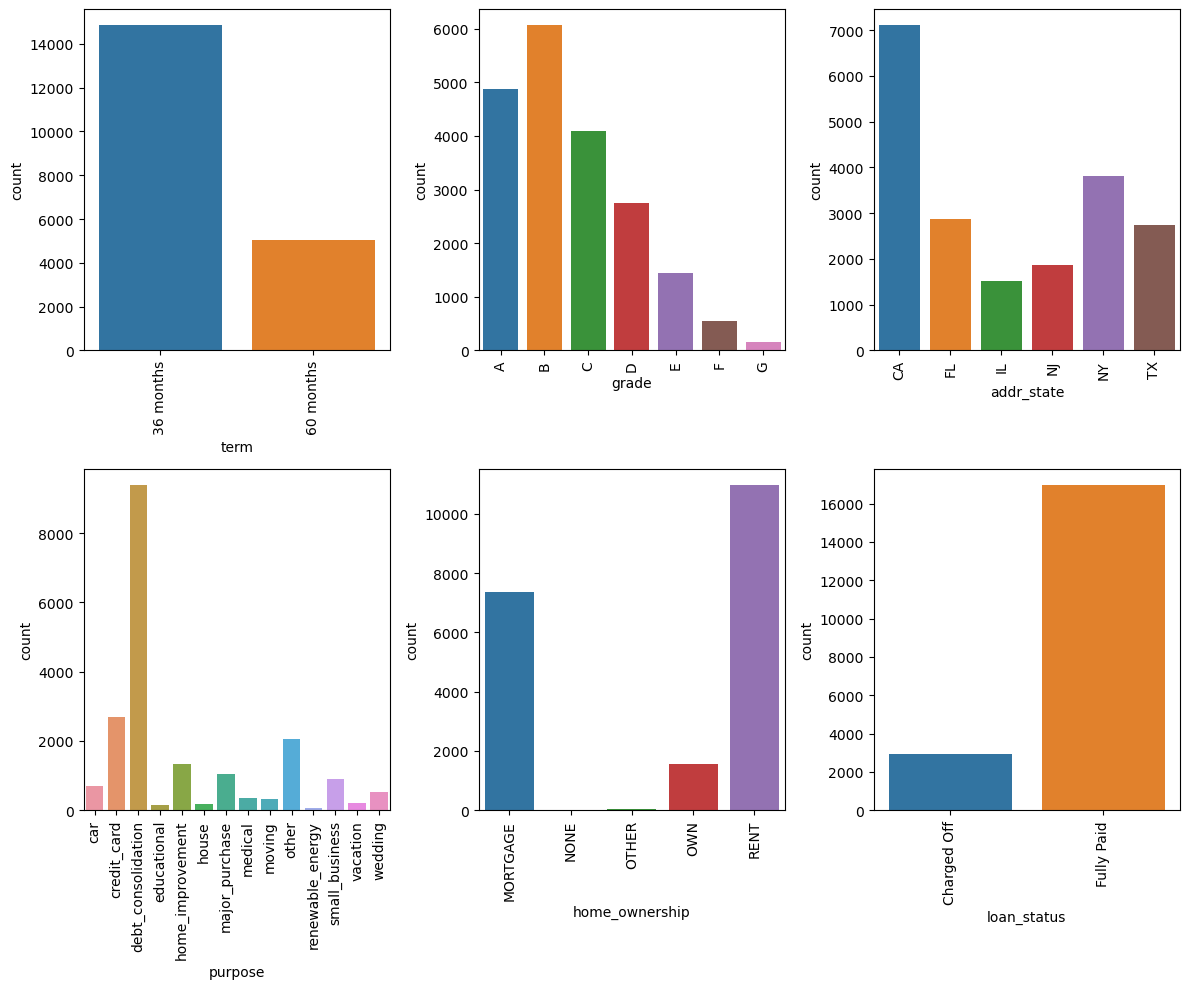

In [7]:
cat_feat = ['term', 'grade', 'addr_state', 'purpose', 'home_ownership', 'loan_status']

plt.figure(figsize=(12,10))

i=1
for col in cat_feat:
    plt.subplot(2,3,i)
    sns.countplot(x=loan_df[col], data=loan_df, order=sorted(loan_df[col].unique()))
    i +=1
    plt.xticks(rotation=90)
    plt.tight_layout()

**__ Findings __**
- Most loans are fully paid (~85%)
- Loans significantly come from:
    - state: CA, NY 
    - for debt_consolidation purpose
    - from renters and mortgage pay
- There are 7 grades loan A - G = high - low
    - The top 3 loan grades are: B, A, C with grade B has the highest amount
    
Term:
- There are two different loan terms, 36 months and 60 months.
- The number of 36-month loans is about ~ 3x more than 60-month loans in the dataset.
    
State:
- most loan are generated from CA (~6k), which is nearly double from NY
- loan from CA and NY made up half of the total loan from all 6 states

### Loan Issued Over Year

Explore the number of loans issued through LendingClub from 2007-2011. 

- Convert the **issue_d** column to a datetime type
- Count of loans in each year
- Create a new column **issue_year** with the year extracted from 'issue_d'

In [8]:
loan_df['issue_d'].value_counts().head()
# the format is month-year

issue_d
Dec-11    1159
Nov-11    1111
Oct-11    1069
Sep-11    1068
Aug-11     974
Name: count, dtype: int64

In [9]:
loan_df['issue_d'] = pd.to_datetime(loan_df['issue_d'], format="%b-%y")
loan_df['issue_year'] = loan_df['issue_d'].dt.year
loan_df[["issue_d", "issue_year"]].head()

,issue_d,issue_year
0,2011-12-01,2011
1,2011-12-01,2011
2,2011-12-01,2011
3,2011-12-01,2011
4,2011-12-01,2011


In [10]:
loan_df.groupby(["issue_year", 'term']).agg({"term":"count"})

term
issue_year term           
2007       36 months    90
2008       36 months   780
2009       36 months  2363
2010       36 months  4399
           60 months  1462
2011       36 months  7220
           60 months  3594

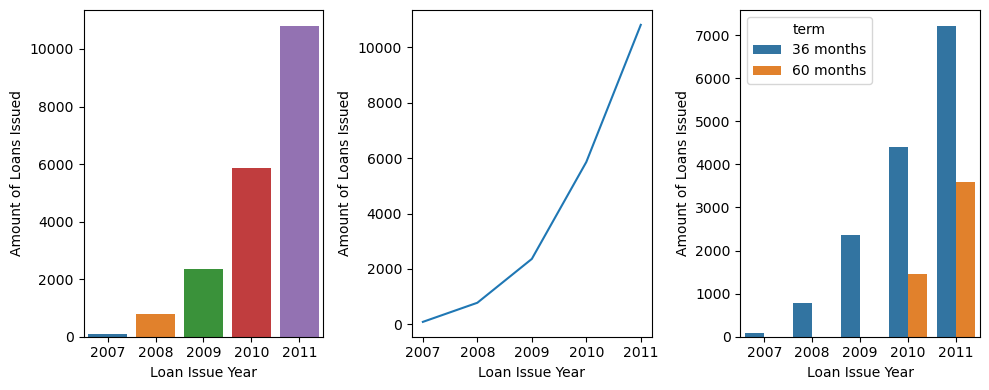

In [11]:
plt.subplots(1,3,figsize=(10,4))

plt.subplot(1,3,1)
sns.countplot(x=loan_df['issue_year'], data=loan_df)
plt.xlabel('Loan Issue Year')
plt.ylabel('Amount of Loans Issued');

plt.subplot(1,3,2)
sns.lineplot(x=loan_df['issue_year'].unique(), y=loan_df['issue_year'].value_counts())
plt.xlabel('Loan Issue Year')
plt.ylabel('Amount of Loans Issued');

plt.subplot(1,3,3)
sns.countplot(x=loan_df['issue_year'], data=loan_df, hue='term')
plt.xlabel('Loan Issue Year')
plt.ylabel('Amount of Loans Issued');

plt.tight_layout()

**__ Findings __**
- the amount of issued loans seems to grow exponentially over the range of 2007 - 2011. 
- loans in 2008 is 8x more than in 2007
- amount of loans increases 2x/year from 2009 to 2011
- 60-month loan term is introduced in 2010

## B2. Interest Rate distribution

Text(0.5, 0, 'Interest Rate (%)')

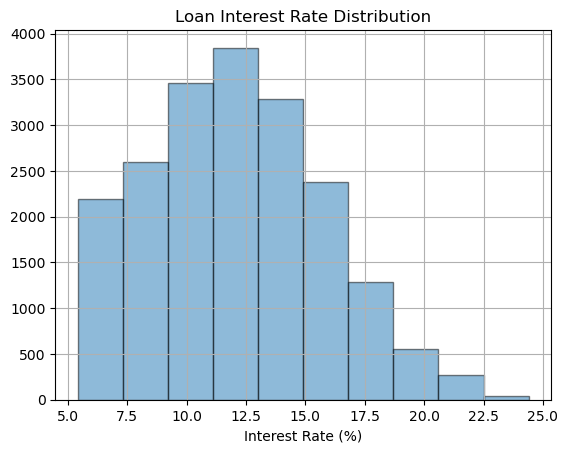

In [12]:
loan_df['int_rate'].hist(edgecolor='black', alpha=0.5)
plt.title('Loan Interest Rate Distribution')
plt.xlabel('Interest Rate (%)')

Interest rate is in the range of 5% to 25%. Majority of loans have interest rate between 5-17%.


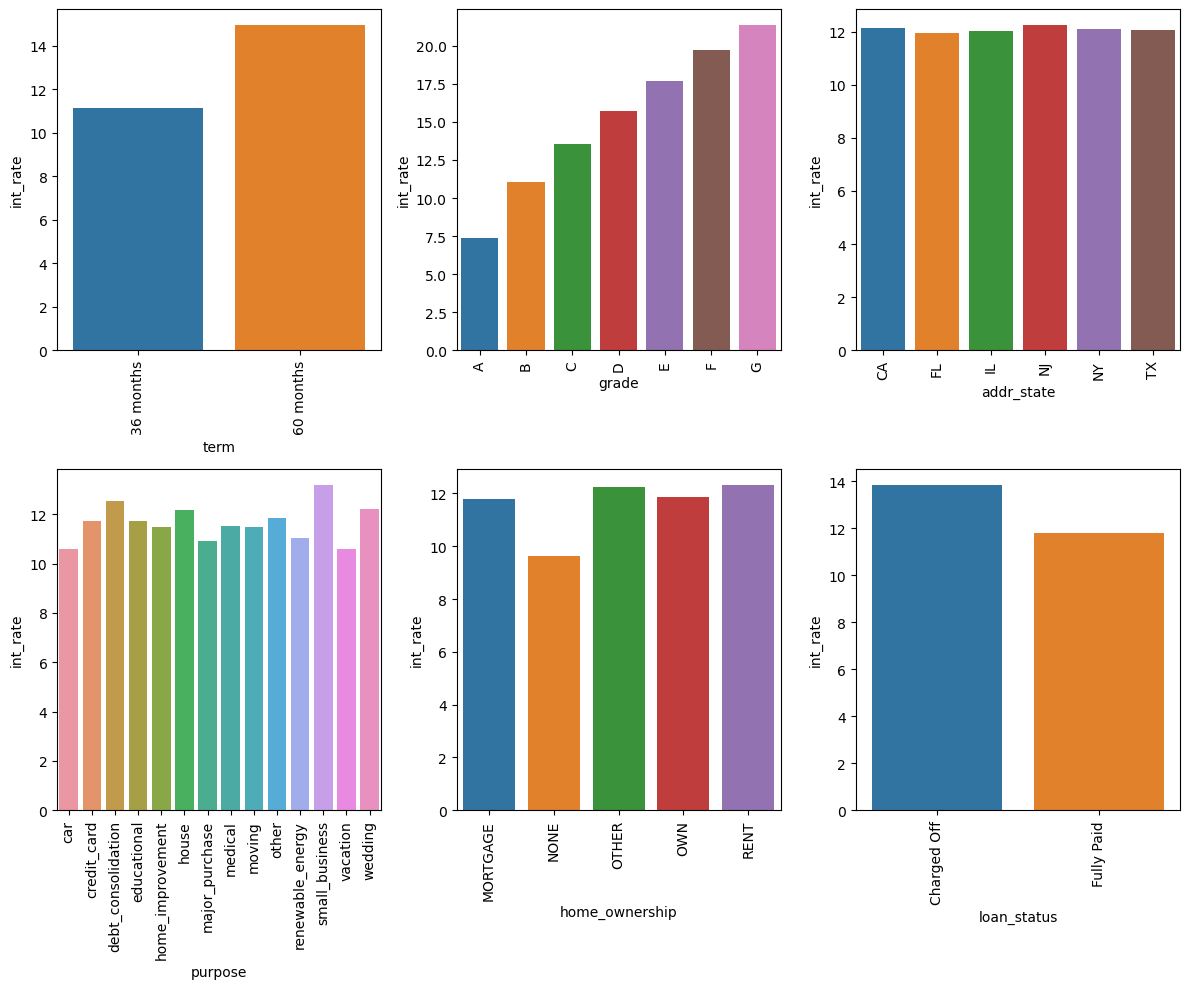

In [13]:
plt.figure(figsize=(12,10))

i=1
for col in cat_feat:
    plt.subplot(2,3,i)
    x = loan_df.groupby(col)['int_rate'].mean().index
    y = loan_df.groupby(col)['int_rate'].mean()
    sns.barplot(x=x, y=y)
    i +=1
    plt.xticks(rotation=90)
    plt.tight_layout()

**__ Findings __**
- 36-month term has a lower average interest rate than 60-month term.
- Paid off loans has lower interest rate.  
- The average interest rate is linear correlated with the loan Grade, descendingly:
    - as loan grade goes lower (A -> G), the interest rate increased
- Grade B loan has the average interest rate of 11.03, which is close to the overall interest rate mean 12.09
- The interest rate are not influenced by state, purpose, nor home ownership status

### Interest Rate Change in each State over Year

In [14]:
year_state = pd.pivot_table(loan_df, index=["issue_year"],
                             columns=["addr_state"], values="int_rate",
                             aggfunc="median")

In [15]:
year_state

addr_state,CA,FL,IL,NJ,NY,TX
issue_year,,,,,,
2007,9.64,10.435,8.54,10.28,10.75,8.225
2008,11.34,10.960,11.14,11.31,11.31,10.995
2009,12.21,12.210,12.18,12.53,12.53,12.840
2010,11.86,11.360,11.49,12.23,11.86,11.490
2011,11.99,11.710,11.99,12.42,11.99,11.710


Text(0, 0.5, 'Median Interest Rate')

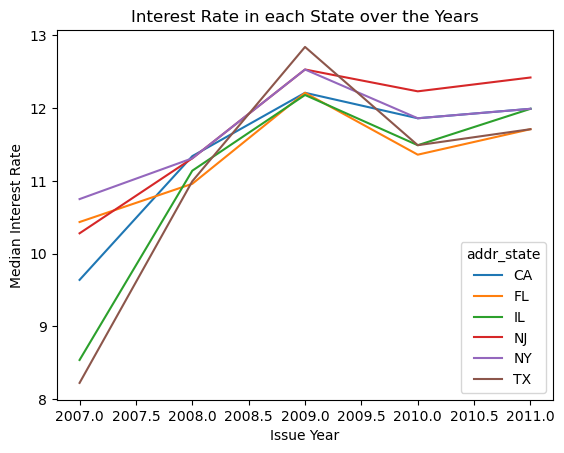

In [16]:
ax = loan_df.pivot_table(index=["issue_year"],
                             columns=["addr_state"], values="int_rate",
                             aggfunc=np.median).plot.line()

ax.set_title('Interest Rate in each State over the Years')
ax.set_xlabel('Issue Year')
ax.set_ylabel('Median Interest Rate')

# plt.figure(figsize=(6,4))

# sns.lineplot(year_state)
# plt.title('Interest Rate in each State over the Years')
# plt.xlabel('Issue Year')
# plt.ylabel('Median Interest Rate')

# plt.tight_layout()

In [17]:
year_state.diff()

addr_state,CA,FL,IL,NJ,NY,TX
issue_year,,,,,,
2007,NaN,NaN,NaN,NaN,NaN,NaN
2008,1.70,0.525,2.60,1.03,0.56,2.770
2009,0.87,1.250,1.04,1.22,1.22,1.845
2010,-0.35,-0.850,-0.69,-0.30,-0.67,-1.350
2011,0.13,0.350,0.50,0.19,0.13,0.220


**__ Findings __**

The interest rate follows a same trend across the 6 states:
- The interest rate increased from 2007 and reached the peak at 2009
- Declined in 2010, and slightly increased in 2011

Some of the steepest increase took place from in 2008 and 2009:
- TX: 2.8% in 2008 and 1.8% in 2009
- IL increased 2.6% in 2008 
- CA: 1.7% in 2008

## B3. Borrowers Annual Income distribution

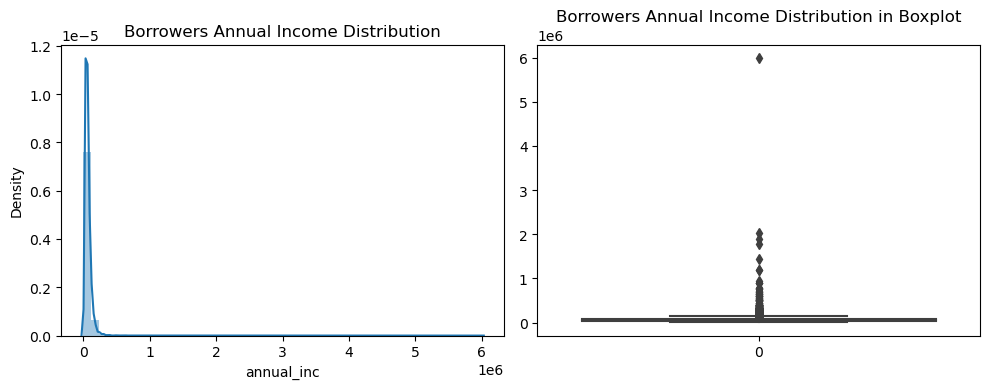

In [18]:
plt.subplots(1,2,figsize=(10,4))

plt.subplot(1,2,1)
sns.distplot(loan_df['annual_inc'])
plt.title('Borrowers Annual Income Distribution');

plt.subplot(1,2,2)
sns.boxplot(loan_df['annual_inc'])
plt.title('Borrowers Annual Income Distribution in Boxplot');

plt.tight_layout()

array([[<Axes: title={'center': 'annual_inc'}>]], dtype=object)

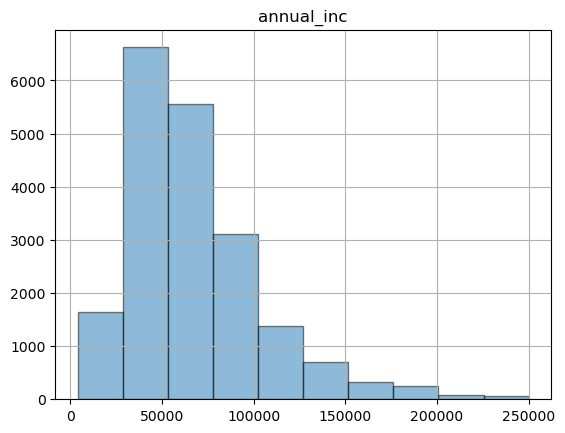

In [19]:
# Since the annual income is very skewed to the right, I need to narrow down range for visualization
loan_df[loan_df['annual_inc'] < 250000].hist(column='annual_inc', edgecolor='black', alpha=0.5)

**__ Findings __**
- The annual income follows a right-skewed distribtuion with a very long right tail.
- There are notable outliers on the right side, with the max annual income of 6M dollars
- The distribution mainly concentrates under 250k dollars

### B3.a. Borrower Annual Income by State

In [20]:
loan_df.groupby('addr_state').agg({'annual_inc':'median'})

,annual_inc
addr_state,
CA,60000.0
FL,53000.0
IL,59500.0
NJ,63000.0
NY,60000.0
TX,60000.0


Text(0, 0.5, 'Median Income')

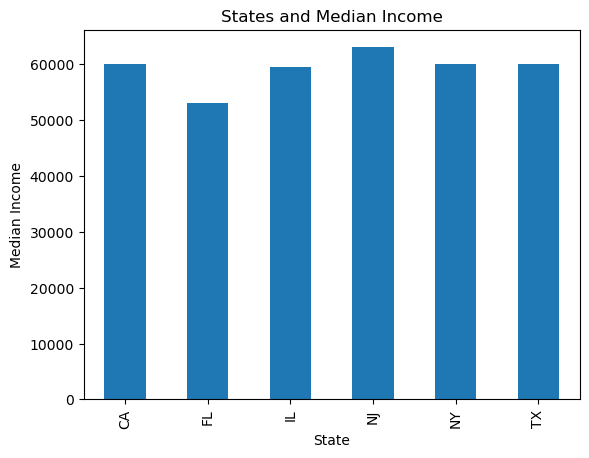

In [21]:
ax = loan_df.groupby('addr_state').agg({'annual_inc':'median'}).plot.bar(legend = False)
ax.set_title('States and Median Income')
ax.set_xlabel('State')
ax.set_ylabel('Median Income')

**__ Findings __**
- The median income across 6 states is similar, around 60k dollars
- Florida median income is the lowest, at 53k dollars

### B3.b. Annual Income and Interest Rate

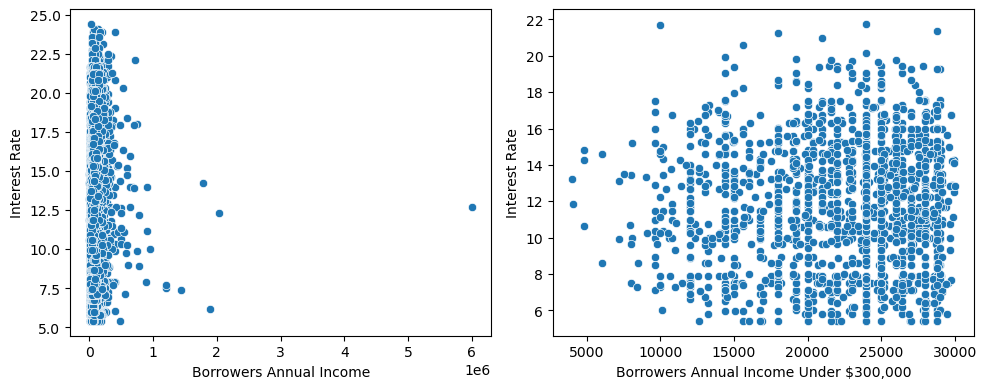

In [22]:
plt.subplots(1,2,figsize=(10,4))

# Full range of annual income
plt.subplot(121)
sns.scatterplot(data=loan_df, x='annual_inc', y='int_rate')
plt.xlabel('Borrowers Annual Income')
plt.ylabel('Interest Rate');

# Annual income < $300,000
plt.subplot(122)
sns.scatterplot(data=loan_df[loan_df['annual_inc']<30000], x='annual_inc', y='int_rate')
plt.xlabel('Borrowers Annual Income Under $300,000')
plt.ylabel('Interest Rate')

plt.tight_layout()

**__ Findings __**
- It looks like there is no correlation between the borrowers' annual income and the interest rate

## B4. Loan Status

The loans in the dataset were issued before 2011 and the longest loan term is 5 years. So all the loans are either paid off or charged off (aka a loss) as of now, 2023

Explore loan status and find out:
- The number of paid off loans and charged off loans
- Paid off rate of the whole dataset.

$PaidOffRate = \frac{FullyPaid}{Fully Paid+Charged Off}$


In [23]:
loan_df.head()

,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,acc_now_delinq,chargeoff_within_12_mths,delinq_amnt,pub_rec_bankruptcies,tax_liens,hardship_flag,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,issue_year
0,1,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252,Not Verified,2011-12-01,Fully Paid,n,small_business,real estate business,606xx,IL,8.72,0,Nov-01,2,NaN,NaN,2,0,2956,98.5,10,f,0,0,3005.666844,3005.67,2400.00,605.67,0.00,0.00,0.00,Jun-14,649.91,NaN,Jun-17,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN,2011
1,2,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200,Source Verified,2011-12-01,Fully Paid,n,other,personel,917xx,CA,20.00,0,Feb-96,1,35.0,NaN,10,0,5598,21.0,37,f,0,0,12231.890000,12231.89,10000.00,2214.92,16.97,0.00,0.00,Jan-15,357.48,NaN,Apr-16,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN,2011
2,3,3000,3000,3000.0,36 months,18.64,109.43,E,E1,MKC Accounting,9 years,RENT,48000,Source Verified,2011-12-01,Fully Paid,n,car,Car Downpayment,900xx,CA,5.35,0,Jan-07,2,NaN,NaN,4,0,8221,87.5,4,f,0,0,3939.135294,3939.14,3000.00,939.14,0.00,0.00,0.00,Jan-15,111.34,NaN,Dec-14,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN,2011
3,4,5600,5600,5600.0,60 months,21.28,152.39,F,F2,NaN,4 years,OWN,40000,Source Verified,2011-12-01,Charged Off,n,small_business,Expand Business & Buy Debt Portfolio,958xx,CA,5.55,0,Apr-04,2,NaN,NaN,11,0,5210,32.6,13,f,0,0,647.500000,647.50,162.02,294.94,0.00,190.54,2.09,Apr-12,152.39,NaN,Oct-16,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN,2011
4,5,5375,5375,5350.0,60 months,12.69,121.45,B,B5,Starbucks,< 1 year,RENT,15000,Verified,2011-12-01,Charged Off,n,other,Building my credit history.,774xx,TX,18.08,0,Sep-04,0,NaN,NaN,2,0,9279,36.5,3,f,0,0,1484.590000,1477.70,673.48,533.42,0.00,277.69,2.52,Nov-12,121.45,NaN,Dec-16,0.0,NaN,1,Individual,0,0.0,0,0.0,0.0,N,Cash,N,NaN,2011


In [24]:
# Overall Paid off rate and Charged Off rate
loan_df['loan_status'].value_counts()/loan_df.shape[0]

loan_status
Fully Paid     0.85217
Charged Off    0.14783
Name: count, dtype: float64

In [25]:
labels = loan_df['loan_status'].value_counts().index

fig = go.Figure(data=[go.Pie(labels=labels, values=loan_df['loan_status'].value_counts())])
fig.show()

#sns.countplot(x="loan_status", data=loan_df)

### Loan Term and Loan Status

In [29]:
pt_term = pd.pivot_table(loan_df, index=["term"],
                         columns=["loan_status"], values="int_rate",
                         aggfunc="count")
pt_term['payoffRate'] = pt_term["Fully Paid"] / (pt_term["Fully Paid"] + pt_term["Charged Off"])
pt_term

loan_status,Charged Off,Fully Paid,payoffRate
term,,,
36 months,1728,13124,0.883652
60 months,1215,3841,0.759691


### Loan Grade and Loan Status

In [30]:
pt_grade = pd.pivot_table(loan_df, index=["grade"],
                         columns=["loan_status"], values="int_rate",
                         aggfunc="count")
pt_grade['payoffRate'] = pt_grade["Fully Paid"] / (pt_grade["Fully Paid"] + pt_grade["Charged Off"])
pt_grade

loan_status,Charged Off,Fully Paid,payoffRate
grade,,,
A,304,4571,0.937641
B,779,5286,0.871558
C,672,3415,0.835576
D,579,2169,0.789301
E,378,1056,0.736402
F,174,366,0.677778
G,57,102,0.641509


**__ Findings __**

Term:
- The overall payoff rate is 85.2%, in which 77% is from 3-year term
- The payoff rate of 3-year term is hihger than 5-year term

Grade:
- Recall: interest rate increase across A - G
- payoffRate decreases across loan grade A - G
- Higher grades (A-C) have lower interest rate and higer payoff rate

## B5. EDA Conclusions

**Impactful features**
Features that seem to have impact on whether a loan will be fully paid are interest rate, loan term, and loan grade. 
- The loan is more likely to be fully paid if the interest rate is low, has a high grade, and in a 3-year term  
- There is no correlation between interest rate and the borrowers' annual income

Although the interest rate varied by states, the same trend took place at across 6 states in which it hiked up most in 2009. States interest rate in 2011 in descendig order is: NJ, NY-CA-IL (tie), TX-FL (tie)

**For model buidling**
The column 'loan_status' is the target column (fully paid - 1, charged off - 0) that a binary classification model is going to predict a loan will be paid off or not. 

---